# PART 1: DATASET LOADING

## STEP 1: IMPORT REQUIRED LIBRARIES

In this step, we import the Python libraries required for our NLP Sentiment Analysis project.

1. Pandas: Used to load and manage datasets.
2. NumPy: Used for numerical operations.
3. Matplotlib: Used to create charts.
4. Seaborn: Used to create visualizations.
5. Warnings: Used to hide unnecessary warning messages.

In [48]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


### Output Explanation

All required Python libraries were imported successfully without any errors.

**Conclusion:** Step 1 completed successfully.

## STEP 2: LOAD THE DATASET

In this step, we load the Samsung customer reviews dataset using the Pandas library.

The dataset contains three columns:

1. title: Contains the customer review heading.
2. rating: Contains the customer rating from 1 to 5.
3. body: Contains the complete customer review.

We use the read_excel() function to load the Excel file.

The head() function displays the first five records.

In [49]:
# Load the dataset

df = pd.read_excel("Dataset (2).xlsx")

# Display first 5 records

df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [50]:
# Check dataset shape

print("Dataset Shape:", df.shape)

Dataset Shape: (1440, 3)


### Output Explanation

The dataset was successfully loaded.

- Total Records: 1,440 customer reviews.
- Total Columns: 3 (title, rating, and body).

**Conclusion:** The dataset is successfully loaded and ready for Exploratory Data Analysis (EDA).

# PART 2: EXPLORATORY DATA ANALYSIS (EDA)

## STEP 3: CHECK DATASET BASIC INFORMATION

In this step, we examine the basic information about our dataset.

We check column names, data types, and dataset information.

This helps us understand the structure of the dataset before data cleaning.

In [51]:
# Display column names

print("Column Names:")
print(df.columns)

# Display data types

print("\nData Types:")
print(df.dtypes)

# Display dataset information

print("\nDataset Information:")
df.info()

Column Names:
Index(['title', 'rating', 'body'], dtype='object')

Data Types:
title     object
rating     int64
body      object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


### Output Explanation

The dataset contains 3 columns: title, rating, and body.

- title: Object (Text).
- rating: Integer (Number).
- body: Object (Text).

The dataset contains 1,440 rows and 3 columns.

All columns contain 1,440 non-null values.

**Conclusion:** We successfully understood the basic structure and data types of our dataset.

## STEP 4: CHECK MISSING VALUES AND DUPLICATE RECORDS

In this step, we check whether the dataset contains missing values or duplicate records.

- Missing Values: Empty cells in the dataset.
- Duplicate Records: Repeated rows in the dataset.

This helps us maintain clean and reliable data before further analysis.

In [52]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records

print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
title     0
rating    0
body      0
dtype: int64

Number of Duplicate Records:
0


### Output Explanation

The dataset contains no missing values in the title, rating, and body columns.

There are also no duplicate records in the dataset.

**Conclusion:** All 1,440 customer records are complete, and no duplicate rows were found.

## STEP 5: STATISTICAL ANALYSIS OF CUSTOMER RATINGS

In this step, we analyze the customer ratings given to the Samsung mobile phone.

We calculate:

1. Count: Total number of ratings.
2. Mean: Average customer rating.
3. Standard Deviation: Variation in ratings.
4. Minimum: Lowest rating.
5. Maximum: Highest rating.
6. Median: Middle value of ratings.

This helps us understand the overall customer rating pattern.

In [53]:
# Statistical summary of customer ratings

df['rating'].describe()

,rating
count,1440.000000
mean,3.173611
std,1.584453
min,1.000000
25%,1.000000
50%,4.000000
75%,5.000000
max,5.000000


### Output Explanation

The statistical summary provides the following information:

- Count: 1,440 customer ratings.
- Mean: Average rating is approximately 3.17.
- Standard Deviation: Approximately 1.58.
- Minimum: 1 star.
- Maximum: 5 stars.
- Median: 4 stars.

**Conclusion:** The average customer rating is approximately 3.17 out of 5.

## STEP 6: DISTRIBUTION OF CUSTOMER RATINGS

In this step, we analyze how customers rated the Samsung mobile phone.

We count the number of reviews for each rating from 1 to 5.

This helps us understand customer satisfaction levels.

We use the value_counts() function to count the ratings.

In [54]:
# Count customer ratings

rating_counts = df['rating'].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

Rating Distribution:
rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


### Output Explanation

The rating distribution shows:

- 1 Star: 386 reviews.
- 2 Stars: 126 reviews.
- 3 Stars: 199 reviews.
- 4 Stars: 310 reviews.
- 5 Stars: 419 reviews.

The highest number of customers gave 5-star ratings.

**Conclusion:** We successfully identified the distribution of customer ratings.

## STEP 7: CREATE SENTIMENT CATEGORIES

In this step, we classify customer reviews into three sentiment categories based on their ratings.

- Positive: Ratings 4 and 5.
- Neutral: Rating 3.
- Negative: Ratings 1 and 2.

This helps us understand customer satisfaction and dissatisfaction.

We use the apply() function to assign sentiment categories.

In [55]:
# Create sentiment categories

def get_sentiment(rating):
    if rating >= 4:
        return 'Positive'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Negative'

df['sentiment'] = df['rating'].apply(get_sentiment)


# Display sentiment counts

print(df['sentiment'].value_counts())

sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


### Output Explanation

The customer reviews are classified into three sentiment categories.

- Positive: 729 reviews.
- Negative: 512 reviews.
- Neutral: 199 reviews.

Positive reviews have the highest count.

**Conclusion:** We successfully classified customer reviews into positive, negative, and neutral categories based on their ratings.

# PART 3: NLP DATA CLEANING

## STEP 8: INSPECT ORIGINAL CUSTOMER REVIEWS

In this step, we examine the original customer reviews before applying NLP preprocessing.

We display a few customer reviews to understand the text format.

This helps us identify uppercase letters, numbers, special characters, and unnecessary spaces.

In [56]:
# Display sample customer reviews

for i in range(5):
    print("Review", i + 1)
    print("Title:", df['title'].iloc[i])
    print("Rating:", df['rating'].iloc[i])
    print("Review:", df['body'].iloc[i])
    print("-" * 150)

Review 1
Title: Horrible product
Rating: 1
Review: Very disappointed with the overall performance from Samsung
------------------------------------------------------------------------------------------------------------------------------------------------------
Review 2
Title: Camera quality is not like 48 megapixel
Rating: 3
Review: Camera quality is low
------------------------------------------------------------------------------------------------------------------------------------------------------
Review 3
Title: Overall
Rating: 4
Review: Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u may get disappointed, it's just normal.The USB cable is too small in lengthIt's a good mobile in this budget, there are no returns for this,  only replacement is available, hence choose wisely before buying
---------------------------------------------

### Output Explanation

The output displays the first five original customer reviews.

We can observe that:

- Some reviews contain uppercase letters.
- Some reviews contain numbers.
- Some reviews contain special characters.
- Some reviews contain unnecessary spaces.
- Reviews have different lengths.

Conclusion: We inspected the original customer reviews and identified the text that needs preprocessing.

## STEP 9: CLEAN CUSTOMER REVIEWS

In this step, we clean the customer reviews before performing sentiment analysis.

We perform the following operations:

1. Combine review title and body.
2. Convert text into lowercase.
3. Remove HTML tags and URLs.
4. Remove unnecessary special characters.
5. Remove extra spaces.

This helps prepare the reviews for NLP preprocessing.

In [57]:
import re

# Combine title and body
df['review'] = df['title'] + ' ' + df['body']

# Define text cleaning function
def clean_text(text):

    text = text.lower()

    # Preserve negative meaning
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bdoesn't\b", "does not", text)
    text = re.sub(r"\bdon't\b", "do not", text)

    # Remove HTML tags and URLs
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply text cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Display results
df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,Horrible product Very disappointed with the ov...,horrible product very disappointed with the ov...
1,Camera quality is not like 48 megapixel Camera...,camera quality is not like megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall got the mobile on the launch date batt...
3,A big no from me 1. It doesn't work with 5.0GH...,a big no from me it does not work with ghz wif...
4,Put your money somewhere else Not worth buying...,put your money somewhere else not worth buying...


### Output Explanation

The output displays the original and cleaned customer reviews.

- Title and body are combined into one review.
- All letters are converted into lowercase.
- HTML tags and URLs are removed.
- Numbers and special characters are removed.
- Extra spaces are removed.

Conclusion: Customer reviews are cleaned and ready for further NLP preprocessing.

## STEP 10: COMPARE ORIGINAL AND CLEANED REVIEWS

In this step, we compare original customer reviews with cleaned reviews.

This helps us understand how the text changes after cleaning.

We display a few reviews for comparison.

In [58]:
# Compare original and cleaned reviews

for i in range(3):
    print("ORIGINAL REVIEW:")
    print(df['review'].iloc[i])

    print("\nCLEANED REVIEW:")
    print(df['cleaned_review'].iloc[i])

    print("-" * 150)

ORIGINAL REVIEW:
Horrible product Very disappointed with the overall performance from Samsung

CLEANED REVIEW:
horrible product very disappointed with the overall performance from samsung
------------------------------------------------------------------------------------------------------------------------------------------------------
ORIGINAL REVIEW:
Camera quality is not like 48 megapixel Camera quality is low

CLEANED REVIEW:
camera quality is not like megapixel camera quality is low
------------------------------------------------------------------------------------------------------------------------------------------------------
ORIGINAL REVIEW:
Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u may get disappointed, it's just normal.The USB cable is too small in lengthIt's a good mobile in this budget, there are no returns fo

### Output Explanation

The output displays three original and cleaned customer reviews.

- Original reviews contain uppercase letters and special characters.
- Cleaned reviews contain lowercase letters.
- Unnecessary special characters and numbers are removed.
- Extra spaces are removed.
- Negative words are preserved.

Conclusion: The comparison confirms that customer reviews have been cleaned successfully.

## STEP 11: ANALYZE CUSTOMER REVIEW LENGTH

In this step, we calculate the length of each cleaned customer review.

We calculate:

1. Character Length: Total number of characters.
2. Word Count: Total number of words.

This helps us understand how customers express their opinions through reviews.

In [59]:
# Calculate review length
df['review_length'] = df['cleaned_review'].str.len()

# Calculate word count
df['word_count'] = df['cleaned_review'].str.split().str.len()

# Display results
df[['cleaned_review', 'review_length', 'word_count']].head()

,cleaned_review,review_length,word_count
0,horrible product very disappointed with the ov...,76,10
1,camera quality is not like megapixel camera qu...,58,10
2,overall got the mobile on the launch date batt...,404,73
3,a big no from me it does not work with ghz wif...,364,74
4,put your money somewhere else not worth buying...,201,36


### Output Explanation

The output displays customer reviews along with their character length and word count.

- Character Length represents the total characters in a review.
- Word Count represents the total words in a review.
- Longer reviews contain more words.
- Shorter reviews contain fewer words.

Conclusion: We successfully calculated the length and word count of customer reviews.

## STEP 12: TOKENIZATION, REMOVE STOPWORDS AND APPLY LEMMATIZATION

In this step, we improve the cleaned customer reviews using NLP techniques.

We perform three operations:

1. Tokenization: Breaks each review into individual words called tokens.

Example:
"This product is very good" → ["this", "product", "is", "very", "good"]

2. Stopword Removal: Removes common words that do not provide much meaning, such as "the", "is", and "are".
3. Lemmatization: Converts words into their base form.

Examples:
- playing → play
- running → run
- better → good

We preserve important negative words such as "not", "no", and "never" because they help identify customer sentiment.

This helps prepare the reviews for machine learning.

In [60]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

### Output Explanation

The NLTK (Natural Language Toolkit) library and its required packages were successfully downloaded and are ready to use for text preprocessing.

- **Tokenization:** Tokenization means breaking a sentence or customer review into individual words called **tokens**.

  **Example:**  
  `"This product is very good"` → `["This", "product", "is", "very", "good"]`

- **Stopwords:** These are commonly used words such as **"the"**, **"is"**, and **"are"**. Removing them helps us focus on more meaningful words.

- **WordNet:** WordNet provides a collection of English words and is used by the **WordNetLemmatizer** to convert words into their base forms.

- **OMW (Open Multilingual WordNet):** Provides additional language resources to support WordNet.

The output shows that the required NLTK packages are already downloaded and up to date.

**Conclusion:** All the required NLTK resources are available and ready for NLP text preprocessing, including tokenization, stopword removal, and lemmatization.

In [61]:
# Import NLTK tokenizer
from nltk.tokenize import word_tokenize

# Download tokenizer package
nltk.download('punkt')
nltk.download('punkt_tab')

# Tokenize the cleaned reviews
df['tokens'] = df['cleaned_review'].apply(word_tokenize)

# Display cleaned review and tokens
df[['cleaned_review', 'tokens']].head()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,cleaned_review,tokens
0,horrible product very disappointed with the ov...,"[horrible, product, very, disappointed, with, ..."
1,camera quality is not like megapixel camera qu...,"[camera, quality, is, not, like, megapixel, ca..."
2,overall got the mobile on the launch date batt...,"[overall, got, the, mobile, on, the, launch, d..."
3,a big no from me it does not work with ghz wif...,"[a, big, no, from, me, it, does, not, work, wi..."
4,put your money somewhere else not worth buying...,"[put, your, money, somewhere, else, not, worth..."


In [62]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Load stopwords
stop_words = set(stopwords.words('english'))

# Preserve negative words
stop_words = stop_words - {
    'no', 'not', 'nor', 'neither', 'never', 'but', 'against', 'off', 'out', 'up', 'down'
}

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

# Define preprocessing function
def preprocess_text(tokens):

    # Remove stopwords
    words = [word for word in tokens if word not in stop_words]

    # Apply lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Convert the processed words back into a sentence
    return ' '.join(words)

# Apply NLP preprocessing
df['processed_review'] = df['tokens'].apply(preprocess_text)

# Display results
df[['cleaned_review','tokens', 'processed_review']].head()

,cleaned_review,tokens,processed_review
0,horrible product very disappointed with the ov...,"[horrible, product, very, disappointed, with, ...",horrible product disappointed overall performa...
1,camera quality is not like megapixel camera qu...,"[camera, quality, is, not, like, megapixel, ca...",camera quality not like megapixel camera quali...
2,overall got the mobile on the launch date batt...,"[overall, got, the, mobile, on, the, launch, d...",overall got mobile launch date battery must ap...
3,a big no from me it does not work with ghz wif...,"[a, big, no, from, me, it, does, not, work, wi...",big no not work ghz wifi frequency ghz old sch...
4,put your money somewhere else not worth buying...,"[put, your, money, somewhere, else, not, worth...",put money somewhere else not worth buying faul...


### Output Explanation

The output displays the cleaned reviews, their tokens, and the final NLP-processed reviews.

The following operations were successfully performed:

1. **Tokenization:** Each cleaned review was broken into individual words called **tokens**. This makes it easier to process each word separately.

2. **Stopword Removal:** Common words such as "the", "is", and "are" were removed to reduce unnecessary words.

3. **Preserving Negative Words:** Important words such as **"not"**, **"no"**, and **"nor"** were preserved because they can help identify negative customer opinions and sentiment.

4. **Lemmatization:** Words were converted into their base forms wherever applicable.

5. **Processed Review Creation:** The final processed text was stored in a new column called `processed_review`.

### Observations

- The reviews were first divided into individual words through tokenization.
- The processed reviews contain fewer unnecessary words.
- Important negative words are preserved.
- Words are converted into simpler base forms where applicable.
- The cleaned reviews, tokens, and processed reviews can be compared to understand the changes made during preprocessing.

**Conclusion:** Tokenization, stopword removal, and lemmatization were successfully applied. The `processed_review` column is now ready for further NLP analysis, sentiment analysis, and machine learning.

## STEP 13: VERIFY NLP PROCESSED REVIEWS

In this step, we verify the final NLP processed customer reviews.

We check the processed review text and confirm that it is ready for further analysis.

This column will be used for sentiment analysis and machine learning.

In [63]:
# Display final processed reviews

df[['rating', 'sentiment', 'processed_review']].head()

,rating,sentiment,processed_review
0,1,Negative,horrible product disappointed overall performa...
1,3,Neutral,camera quality not like megapixel camera quali...
2,4,Positive,overall got mobile launch date battery must ap...
3,1,Negative,big no not work ghz wifi frequency ghz old sch...
4,1,Negative,put money somewhere else not worth buying faul...


### Output Explanation

The output displays the rating, sentiment category, and NLP processed reviews.

- Rating represents the original customer rating.
- Sentiment represents the positive, negative, or neutral category.
- Processed Review contains text after stopword removal and lemmatization.

Conclusion: The NLP processed review column is ready for further sentiment analysis.

# PART 4: DATA VISUALIZATION

## STEP 14: VISUALIZE REVIEW LENGTH BY SENTIMENT

In this step, we visualize customer review lengths based on sentiment categories.

We use a hist plot to compare the review lengths of positive, negative, and neutral reviews.

This helps us understand how review lengths differ across sentiment categories.

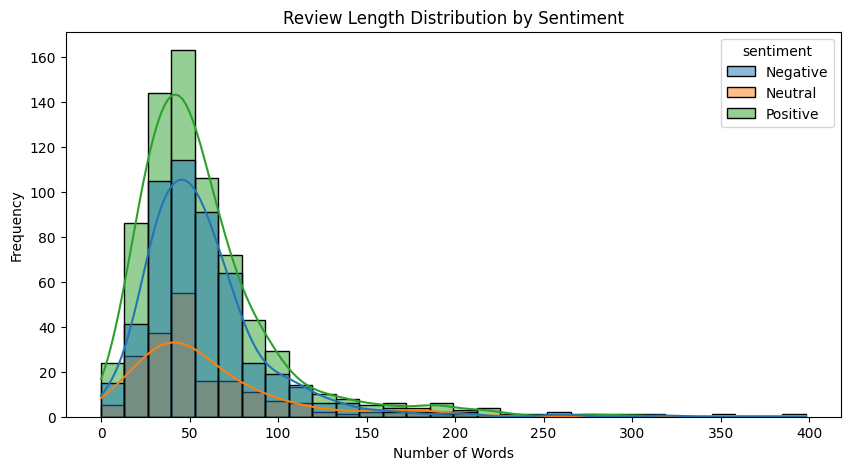

In [64]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=30,
    kde=True
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

Output Explanation

The histogram compares customer review lengths across different sentiment categories.
- X-axis: Displays the number of words in customer reviews.
- Y-axis: Represents the frequency or number of reviews.
- Colors: Represent different sentiment categories, such as positive, negative, and neutral.
- Bars: Show how many reviews fall within a particular word-count range.
- KDE Curve: Shows the smooth distribution pattern of review lengths for each sentiment.

Observations:
1. We can compare the distribution of review lengths for each sentiment category.
2. We can identify which sentiment has more short or long reviews.
3. Higher bars indicate that more reviews fall within that particular word-count range.
4. The KDE curves help us understand the overall pattern and spread of review lengths.

Conclusion:

The histogram helps us understand how customer review lengths are distributed across different sentiment categories. It allows us to identify whether positive, negative, or neutral reviews tend to be shorter, longer, or have different distribution patterns.

## STEP 15: VISUALIZE CUSTOMER SENTIMENT DISTRIBUTION

In this step, we create a bar chart to visualize customer sentiment categories.

We display the number of positive, negative, and neutral reviews.

This helps us understand the overall customer satisfaction level.

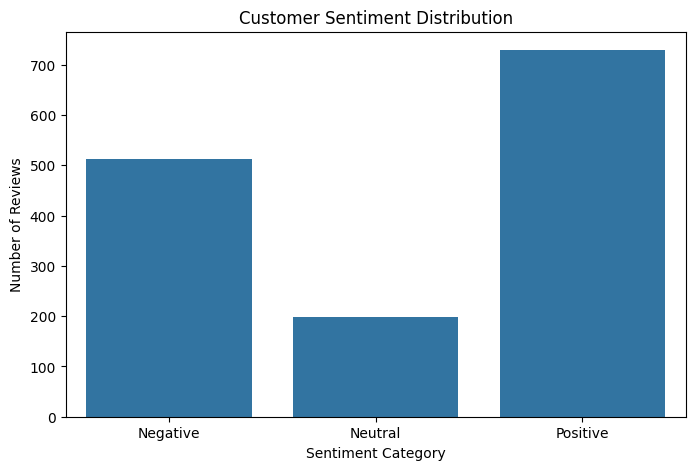

In [65]:
# Visualize customer sentiment distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='sentiment',
    order=['Negative', 'Neutral', 'Positive']
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")

plt.show()

### Output Explanation

The bar chart shows the distribution of customer sentiment categories.

Observations:

- Positive: 729 reviews.
- Negative: 512 reviews.
- Neutral: 199 reviews.

1. Positive reviews have the highest count.
2. Negative reviews are the second highest.
3. Neutral reviews have the lowest count.

Conclusion: Most customers expressed positive opinions about the Samsung mobile phone, while a considerable number expressed negative opinions.

## STEP 16: FIND FREQUENTLY USED WORDS USING COUNTVECTORIZER

In this step, we identify the most frequently used words in customer reviews.

We use CountVectorizer to count how many times each word appears.

This helps us identify the common topics discussed by customers.

We display the top 10 frequently used words using a bar chart.



1. **sklearn:** Stands for Scikit-learn. It is a Python library used for machine learning.

2. **feature_extraction:** A module used to convert raw data into numerical features.

3. **text:** A module that provides tools for processing text data.

4. **CountVectorizer:** Converts text into numerical values by counting how many times each word appears.

5. **vectorizer = CountVectorizer():** Creates a CountVectorizer object to identify and count words in customer reviews.

6. **fit():** Identifies all unique words from the customer reviews and creates a vocabulary.

7. **transform():** Converts customer reviews into numerical word counts.

8. **fit_transform():** Performs both vocabulary creation and text conversion in a single step.

9. **X:** Stores the numerical representation of customer reviews.

10. **sum(axis=0):** Adds the frequency of each word across all customer reviews.


In [66]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer
vectorizer = CountVectorizer()

# Convert reviews into word counts
X = vectorizer.fit_transform(df['processed_review'])

# Calculate word frequency
word_counts = X.sum(axis=0).A1

# Create frequency DataFrame
word_freq = pd.DataFrame({
    'Word': vectorizer.get_feature_names_out(),
    'Frequency': word_counts
})

# Display top 10 frequent words
top_words = word_freq.sort_values(
    by='Frequency', ascending=False
).head(10)

print(top_words)

         Word  Frequency
3108    phone       2006
2849      not       1832
1792     good       1480
630    camera       1110
387   battery        897
3728  samsung        807
603       but        751
3383  quality        726
2694   mobile        646
3265    price        462


11. **.A1:** Converts the result into a one-dimensional NumPy array.

12. **get_feature_names_out():** Returns all unique words identified by CountVectorizer.

13. **Word:** Stores the unique words identified from customer reviews.

14. **Frequency:** Stores the total number of times each word appears.

15. **sort_values():** Arranges the words based on their frequency.

16. **by='Frequency':** Specifies that sorting should be performed using the Frequency column.

17. **ascending=False:** Sorts the frequencies from highest to lowest.

18. **head(10):** Selects the first 10 rows containing the most frequently used words.

19. **print(top_words):** Displays the final top 10 frequently used words along with their frequencies.

**Conclusion:** We successfully used CountVectorizer to convert customer reviews into numerical data and identify the 10 most frequently used words.

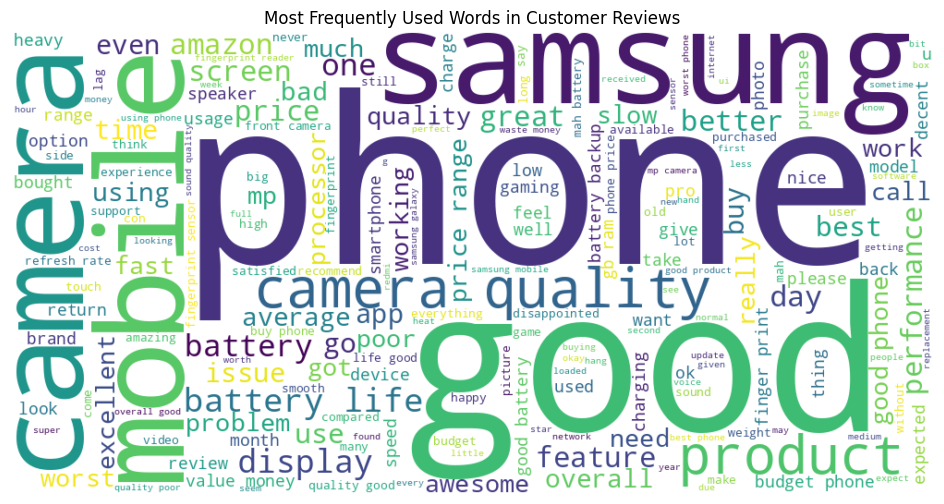

In [67]:
from wordcloud import WordCloud

# Combine all processed reviews into one text
all_words = ' '.join(df['processed_review'].dropna())

# Create WordCloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(all_words)

# Display WordCloud
plt.figure(figsize=(12, 6))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title("Most Frequently Used Words in Customer Reviews")

plt.show()

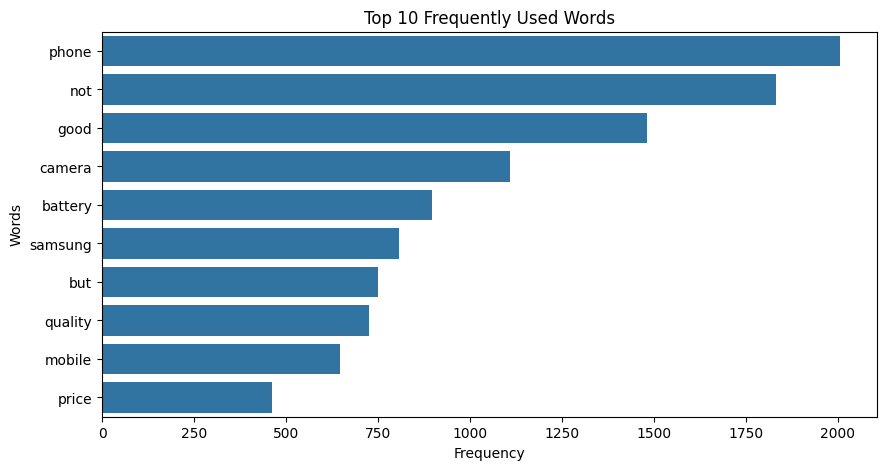

In [68]:
# Visualize top 10 frequent words

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_words,
    x='Frequency',
    y='Word'
)

plt.title("Top 10 Frequently Used Words")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

### Output Explanation

The output displays the top 10 most frequently used words in customer reviews.

- Word: Represents a frequently used word.
- Frequency: Represents how many times the word appears.

Observations:

1. The table identifies the most commonly used words.
2. Words with higher frequencies appear more often.
3. The bar chart makes it easier to compare word frequencies.
4. These words help us understand the common topics discussed by customers.

Conclusion: CountVectorizer successfully identifies frequently used words in customer reviews and helps us understand customer feedback.

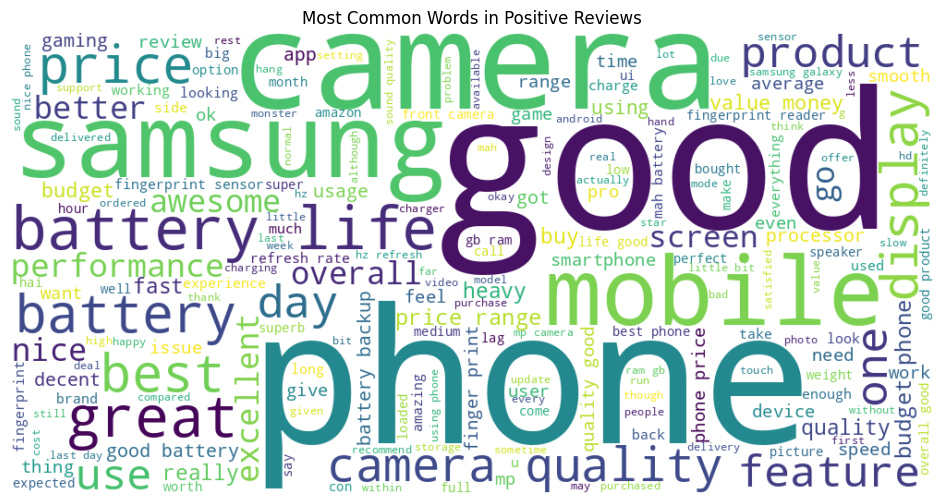

Top 10 Most Frequent Words in Negative Reviews


,Word,Frequency
0,good,1076
1,phone,1022
2,camera,615
3,battery,600
4,not,580
5,but,405
6,quality,351
7,price,340
8,samsung,327
9,mobile,235


In [69]:
from wordcloud import WordCloud
from collections import Counter

# Combine all positive reviews
positive_text = ' '.join(
    df[df['sentiment'] == 'Positive']['processed_review'].dropna()
)

# Create WordCloud
positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

# Display WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Positive Reviews')
plt.show()

# Create frequency table AFTER the WordCloud
positive_word_freq = Counter(positive_text.split())

positive_frequency_table = pd.DataFrame(
    positive_word_freq.most_common(10),
    columns=['Word', 'Frequency']
)

print("Top 10 Most Frequent Words in Negative Reviews")
display(positive_frequency_table)

**Output Explanation**

The output displays a WordCloud containing the most frequently used words in Positive customer reviews.
- Large Words: Represent words used more frequently in positive reviews.
- Small Words: Represent words used less frequently.

Observations:

1. The WordCloud focuses only on customers with Positive sentiment.
2. Frequently used words appear larger.
3. These words can help us understand what customers like about the product or service.
4. The visualization makes positive customer feedback easier to understand.

Conclusion:

The Positive WordCloud helps identify the common words and topics associated with satisfied customers.


**Output Explanation**

The output displays the top 10 most frequently used words in Positive customer reviews.
- Word: Represents a frequently used word in positive reviews.
- Frequency: Represents how many times the word appears.

Observations:
1. The table identifies the most common words used by satisfied customers.
2. Words with higher frequencies appear more often in positive feedback.
3. These words can help identify the features or topics customers appreciate.
4. The results provide a better understanding of positive customer opinions.

Conclusion:

The frequency table helps identify common words in Positive reviews and provides useful insights into customer satisfaction.

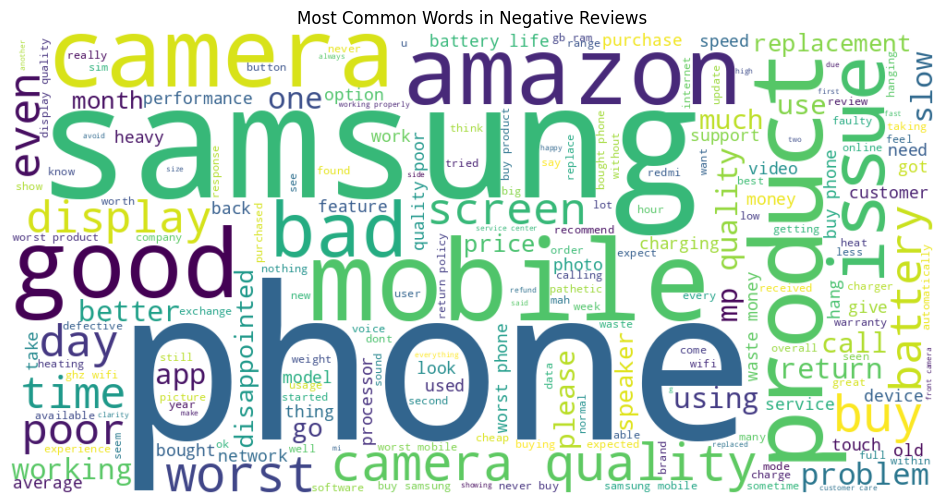

Top 10 Most Frequent Words in Negative Reviews


,Word,Frequency
0,not,899
1,phone,700
2,samsung,378
3,camera,306
4,mobile,304
5,quality,252
6,product,241
7,buy,217
8,but,206
9,worst,198


In [70]:
# Combine all Negative reviews
negative_text = ' '.join(
    df[df['sentiment'] == 'Negative']['processed_review'].dropna().astype(str)
)

# Create and display WordCloud
negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Negative Reviews')
plt.show()


# Create frequency table AFTER the WordCloud
negative_word_freq = Counter(negative_text.split())

negative_frequency_table = pd.DataFrame(
    negative_word_freq.most_common(10),
    columns=['Word', 'Frequency']
)

print("Top 10 Most Frequent Words in Negative Reviews")
display(negative_frequency_table)

**Explanation**
The output displays a WordCloud containing the most frequently used words in Negative customer reviews.
- Large Words: Represent words that appear more frequently in negative reviews.
- Small Words: Represent words that appear less frequently.

Observations:
1. The WordCloud focuses only on customers with Negative sentiment.
2. Frequently used words appear larger and are easier to identify.
3. These words may highlight common problems or concerns faced by customers.
4. The visualization helps us understand the main topics in negative feedback.

Conclusion:

The Negative WordCloud helps identify commonly discussed problems and areas that may need improvement.

Output Explanation
The output displays the top 10 most frequently used words in Negative customer reviews.
- Word: Represents a frequently used word in negative reviews.
- Frequency: Represents how many times the word appears.
Observations:
1. The table identifies the words most commonly used by dissatisfied customers.
2. Words with higher frequencies appear more often in negative feedback.
3. These words can help identify common customer complaints or issues.
4. The results can be useful for understanding areas that need improvement.
Conclusion:
The frequency table helps identify common words in Negative reviews and provides insights into customer concerns.

### **Import Machine Learning Libraries**

In [71]:
# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


**Explanation**

This cell imports the libraries required for machine learning.
- **train_test_split:** Divides data into training and testing sets.
- **TfidfVectorizer:** Converts text into numerical features based on word importance.
- **Pipeline:** Combines multiple machine learning steps into a single workflow.
- **LinearSVC:** A supervised machine learning classification algorithm.
- **Evaluation metrics:**Used to measure model performance.

#### **Splitting Dataset into training and testing set**

In [72]:
X = df["processed_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1152
Testing samples: 288


**Explanation**

This cell prepares the data for machine learning.
- X contains the review text.
- y contains the sentiment category.
- 80% of the data is used for training.
- 20% is used for testing.
- stratify=y helps maintain the same proportion of Positive, Negative, and Neutral reviews in both datasets.

## **Model 1 : Logistic Regression Model**


In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF features
baseline_vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfidf_baseline = baseline_vectorizer.fit_transform(X_train)
X_test_tfidf_baseline = baseline_vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf_baseline.shape)
print("Testing data shape:", X_test_tfidf_baseline.shape)

Training data shape: (1152, 4323)
Testing data shape: (288, 4323)


### Logistic Regression Model Training

In [74]:
# Logistic Regression Model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf_baseline, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_tfidf_baseline)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In this step, we use **Logistic Regression** to classify customer reviews into different sentiment categories.

- **TF-IDF Features:** The customer reviews are first converted into numerical features using TF-IDF.
- **Logistic Regression:** The model learns the relationship between the review features and their corresponding sentiment labels.
- **max_iter=1000:** Allows the model enough iterations to complete the training process.
- **random_state=42:** Ensures consistent results when the code is run multiple times.
- **Model Training:** The `fit()` function trains the model using the training data.
- **Prediction:** The `predict()` function predicts the sentiment labels for the test data.

The predicted results are stored in `y_pred_lr` and are used later to evaluate the performance of the Logistic Regression model.

### Logistic Regression Evaluation

In [75]:
print("Logistic Regression Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_lr, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_lr, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation

Accuracy: 0.7743055555555556
Precision: 0.7166554684937038
Recall: 0.7743055555555556
F1-Score: 0.7309628053655746

Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.84      0.81       102
     Neutral       0.29      0.05      0.09        40
    Positive       0.79      0.92      0.85       146

    accuracy                           0.77       288
   macro avg       0.62      0.61      0.58       288
weighted avg       0.72      0.77      0.73       288



#### Model Evaluation and Result Interpretation: Logistic Regression model

The Logistic Regression model achieved an **overall accuracy of 77.43%**, which means it correctly predicted approximately 77% of the customer reviews.

**Evaluation Metrics:**

- **Accuracy (77.43%):** The model correctly predicted 77.43% of the total test samples.
- **Precision (71.67%):** Indicates the correctness of the model's predicted sentiment classes using weighted averaging.
- **Recall (77.43%):** Shows how many actual sentiment samples were correctly identified.
- **F1-Score (73.10%):** Represents the balance between precision and recall using weighted averaging.

**Classification Report Interpretation:**

1. **Negative reviews:**
   - Precision: **0.77**
   - Recall: **0.84**
   - F1-Score: **0.81**
   - The model performs well in identifying negative reviews, correctly detecting 84% of actual negative reviews.

2. **Neutral reviews:**
   - Precision: **0.29**
   - Recall: **0.05**
   - F1-Score: **0.09**
   - The model performs poorly in identifying neutral reviews. It correctly detects only 5% of actual neutral reviews.

3. **Positive reviews:**
   - Precision: **0.79**
   - Recall: **0.92**
   - F1-Score: **0.85**
   - The model performs best in identifying positive reviews, with 92% recall.

**Overall Observation:**

The model performs well in classifying positive and negative reviews but struggles significantly with neutral sentiment. Its very low neutral recall indicates that most actual neutral reviews are incorrectly classified into other sentiment categories.

**Conclusion:**

The Logistic Regression model achieved **77.43% accuracy** and a **weighted F1-score of 73.10%**, showing reasonably good overall performance. However, its poor performance on neutral reviews indicates that further improvements are needed to achieve better classification across all sentiment categories.

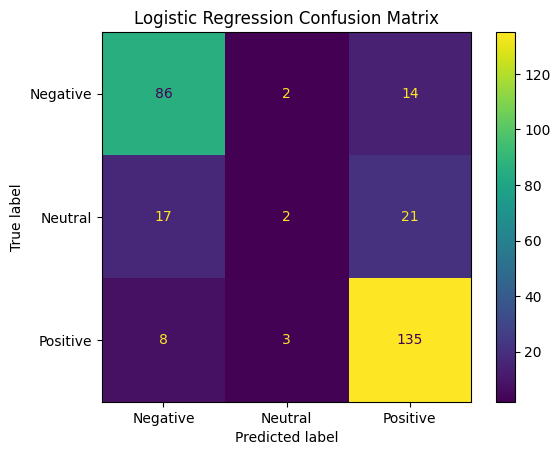

In [76]:
# Logistic Regression Confusion Matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=sorted(y_test.unique())
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## **Model 2: TF-IDF + Linear SVM**

In [77]:
# Create pipeline
tfidf_svm_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('svm', LinearSVC())
])

### Model Training using TF-IDF and Linear SVC

In [ ]:
# Train the model
tfidf_svm_model.fit(X_train, y_train)

# Predictions
y_pred_tfidf = tfidf_svm_model.predict(X_test)


In this step, we create a Machine Learning pipeline that combines TF-IDF vectorization and Linear SVC classification.

- **TF-IDF:** Converts text reviews into numerical features, considering a maximum of 5,000 features.
- **Linear SVC:** Trains a classification model to identify sentiment categories.
- **Model Training:** The `fit()` function trains the model using training data (`X_train`, `y_train`).
- **Prediction:** The `predict()` function predicts sentiment labels for the test data (`X_test`).

The predicted results are stored in `y_pred_tfidf` for further model evaluation.

### TF-IDF + Linear SVM evaluation

In [78]:
print("TF-IDF + Linear SVM Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_tfidf))

print("Precision:",
      precision_score(y_test, y_pred_tfidf, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_tfidf, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_tfidf, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_tfidf))

TF-IDF + Linear SVM Evaluation

Accuracy: 0.7743055555555556
Precision: 0.7434249125277351
Recall: 0.7743055555555556
F1-Score: 0.7544256704538148

Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.84      0.80       102
     Neutral       0.33      0.17      0.23        40
    Positive       0.84      0.89      0.86       146

    accuracy                           0.77       288
   macro avg       0.65      0.64      0.63       288
weighted avg       0.74      0.77      0.75       288



### Model Evaluation and Result Interpretation: TF-IDF + Linear SVM

The TF-IDF + Linear SVM model achieved an overall accuracy of **77.43%**, indicating that the model correctly classified approximately 77% of the test reviews.

**Evaluation Metrics:**

- **Accuracy (77.43%):** The model correctly predicted 77.43% of the total test samples.
- **Precision (74.34%):** Indicates the overall correctness of the model's positive predictions across sentiment classes, using weighted averaging.
- **Recall (77.43%):** Shows that the model identified 77.43% of the actual sentiment samples correctly.
- **F1-Score (75.44%):** Represents the balance between precision and recall.

**Classification Report Interpretation:**

1. **Negative Sentiment:**
   - Precision: 0.77
   - Recall: 0.84
   - F1-Score: 0.80
   - The model performs well in identifying negative reviews.

2. **Neutral Sentiment:**
   - Precision: 0.33
   - Recall: 0.17
   - F1-Score: 0.23
   - The model struggles to identify neutral reviews correctly. Many neutral reviews are being classified into other sentiment categories.

3. **Positive Sentiment:**
   - Precision: 0.84
   - Recall: 0.89
   - F1-Score: 0.86
   - The model performs best in identifying positive reviews.

**Overall Observation:**

The model performs well for positive and negative sentiment classification but struggles with neutral sentiment. This may be due to fewer neutral samples in the dataset compared to positive and negative samples.

**Conclusion:**

The TF-IDF + Linear SVM model achieved 77.43% accuracy and performed better in identifying positive and negative sentiments. However, neutral sentiment classification needs improvement. Further techniques such as hyperparameter tuning, class balancing, and additional text preprocessing can help improve the model's performance.

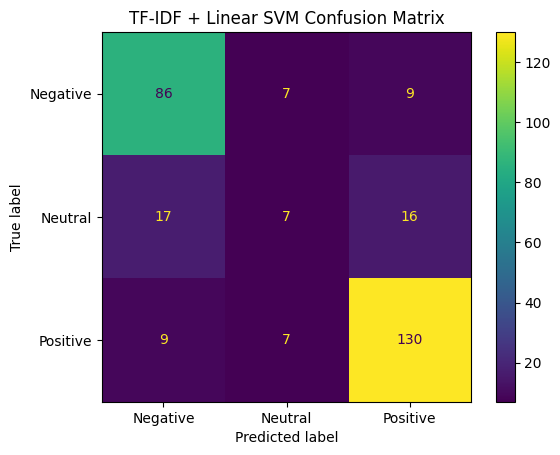

In [79]:
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tfidf,
    display_labels=tfidf_svm_model.classes_
)

disp.plot()
plt.title("TF-IDF + Linear SVM Confusion Matrix")
plt.show()

## **Model 3: Optimized TF-IDF + Linear SVM**

### Optimized TF-IDF + Linear SVM Model Training


In [80]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

# Create TF-IDF features using unigrams and bigrams
optimized_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_opt = optimized_vectorizer.fit_transform(X_train)
X_test_opt = optimized_vectorizer.transform(X_test)

# Define parameters for tuning
param_grid = {
    'C': [0.01, 0.1, 0.5, 1, 2, 5, 10]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=LinearSVC(
        random_state=42,
        max_iter=5000
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)


# Train different model combinations
grid_search.fit(X_train_opt, y_train)

# Get the best model
best_svm = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'C': 2}


In this step, we improve the TF-IDF + Linear SVM model by using more features and parameter tuning.

- **10,000 Features:** The optimized TF-IDF vectorizer uses up to 10,000 features, allowing the model to consider more words from the reviews.
- **Unigrams and Bigrams:** `ngram_range=(1, 2)` considers both individual words and combinations of two consecutive words.
- **GridSearchCV:** Tests different values of the `C` parameter to find the best model configuration.
- **Linear SVM:** Classifies the reviews into their respective sentiment categories.
- **Best Model:** GridSearchCV selects the parameter value that provides the best performance during training.
- **Prediction:** The optimized model predicts sentiment labels for the test data.

The predicted results are stored in `y_pred_optimized_svm` and are used to evaluate and compare the optimized model with the other models.

#### Optimized TF-IDF + Linear SVM Evaluation

In [81]:
y_pred_optimized_svm = best_svm.predict(X_test_opt)

print("Optimized TF-IDF + Linear SVM Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_optimized_svm))

print("Precision:",
      precision_score(
          y_test,
          y_pred_optimized_svm,
          average='weighted'
      ))

print("Recall:",
      recall_score(
          y_test,
          y_pred_optimized_svm,
          average='weighted'
      ))

print("F1-Score:",
      f1_score(
          y_test,
          y_pred_optimized_svm,
          average='weighted'
      ))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_optimized_svm))

Optimized TF-IDF + Linear SVM Evaluation

Accuracy: 0.7881944444444444
Precision: 0.7558282614778837
Recall: 0.7881944444444444
F1-Score: 0.7638599624210125

Classification Report:

              precision    recall  f1-score   support

    Negative       0.78      0.83      0.81       102
     Neutral       0.41      0.17      0.25        40
    Positive       0.83      0.92      0.88       146

    accuracy                           0.79       288
   macro avg       0.67      0.64      0.64       288
weighted avg       0.76      0.79      0.76       288



### Optimized TF-IDF + Linear SVM Evaluation – Explanation

The Optimized TF-IDF + Linear SVM model achieved an overall accuracy of **78.82%**, indicating that it correctly classified approximately 79% of the test reviews.

**Evaluation Metrics:**

- **Accuracy (78.82%):** The model correctly predicted 78.82% of the total test samples.
- **Precision (75.58%):** Indicates the correctness of the model's predicted sentiment classes using weighted averaging.
- **Recall (78.82%):** Shows how many actual sentiment samples were correctly identified.
- **F1-Score (76.39%):** Represents the balance between precision and recall using weighted averaging.

**Classification Report Interpretation:**

1. **Negative reviews:**
   - Precision: **0.78**
   - Recall: **0.83**
   - F1-Score: **0.81**
   - The model performs well in identifying negative reviews, correctly detecting 83% of actual negative reviews.

2. **Neutral reviews:**
   - Precision: **0.41**
   - Recall: **0.17**
   - F1-Score: **0.25**
   - The model shows limited performance in identifying neutral reviews. It correctly detects only 17% of actual neutral reviews.

3. **Positive reviews:**
   - Precision: **0.83**
   - Recall: **0.92**
   - F1-Score: **0.88**
   - The model performs best in identifying positive reviews, with 92% recall.

**Overall Observation:**

The model performs well in classifying positive and negative reviews but struggles with neutral sentiment. Although optimization improved the overall performance, neutral reviews are still frequently misclassified.

**Conclusion:**

The Optimized TF-IDF + Linear SVM model achieved **78.82% accuracy** and a **weighted F1-score of 76.39%**, showing good overall performance. However, further improvement is needed to identify neutral reviews more accurately.


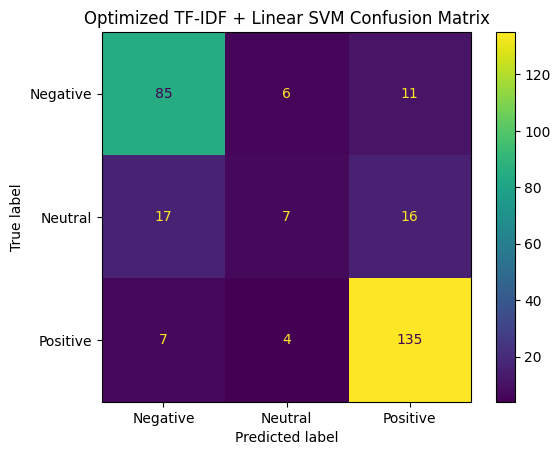

In [82]:
# Optimized SVM Confusion Matrix

cm_optimized_svm = confusion_matrix(
    y_test,
    y_pred_optimized_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_optimized_svm,
    display_labels=sorted(y_test.unique())
)

disp.plot()
plt.title("Optimized TF-IDF + Linear SVM Confusion Matrix")
plt.show()

## **Model 4: Sentence-BERT + Linear SVM**

### Model Training using Sentence-BERT and Linear SVC

In [83]:
from sentence_transformers import SentenceTransformer
from sklearn.svm import LinearSVC

# Load Sentence-BERT model
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Convert text into embeddings
X_train_embeddings = sbert_model.encode(
    X_train.tolist(),
    show_progress_bar=True
)

X_test_embeddings = sbert_model.encode(
    X_test.tolist(),
    show_progress_bar=True
)

# Train Linear SVM
sbert_svm_model = LinearSVC()
sbert_svm_model.fit(X_train_embeddings, y_train)

# Predictions
y_pred_sbert = sbert_svm_model.predict(X_test_embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/36 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

In this step, we use Sentence-BERT to convert text reviews into meaningful numerical embeddings and train a Linear SVC classification model.

- **Sentence-BERT:** Converts text reviews into numerical embeddings while capturing their semantic meaning and context.
- **all-MiniLM-L6-v2:** A pre-trained Sentence-BERT model used to generate sentence embeddings.
- **Text Embeddings:** The `encode()` function converts training and testing reviews into numerical vectors.
- **Linear SVC:** Trains a classification model to identify different sentiment categories.
- **Model Training:** The `fit()` function trains the model using training embeddings (`X_train_embeddings`) and sentiment labels (`y_train`).
- **Prediction:** The `predict()` function predicts sentiment labels for the test embeddings (`X_test_embeddings`).

The predicted results are stored in `y_pred_sbert` for further model evaluation.

#### Sentence-BERT + Linear SVM evaluation

In [84]:
print("Sentence-BERT + Linear SVM Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_sbert))

print("Precision:",
      precision_score(y_test, y_pred_sbert, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_sbert, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_sbert, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_sbert))

Sentence-BERT + Linear SVM Evaluation

Accuracy: 0.7986111111111112
Precision: 0.7668650793650794
Recall: 0.7986111111111112
F1-Score: 0.7694750686441303

Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.90      0.83       102
     Neutral       0.46      0.15      0.23        40
    Positive       0.85      0.90      0.87       146

    accuracy                           0.80       288
   macro avg       0.69      0.65      0.64       288
weighted avg       0.77      0.80      0.77       288



### Model Evaluation and Result Interpretation: Sentence-BERT + Linear SVM

The Sentence-BERT + Linear SVM model achieved an overall accuracy of **79.86%**, indicating that the model correctly classified approximately 80% of the test reviews.

**Evaluation Metrics:**

- **Accuracy (79.86%):** The model correctly predicted 79.86% of the total test samples.
- **Precision (76.69%):** Measures the correctness of predicted sentiment classes using weighted averaging.
- **Recall (79.86%):** Shows how many actual sentiment samples were correctly identified.
- **F1-Score (76.95%):** Represents the balance between precision and recall.

**Classification Report Interpretation:**

1. **Negative Sentiment:**
   - Precision: 0.77
   - Recall: 0.90
   - F1-Score: 0.83
   - The model performs well in identifying negative reviews, correctly detecting 90% of actual negative reviews.

2. **Neutral Sentiment:**
   - Precision: 0.46
   - Recall: 0.15
   - F1-Score: 0.23
   - The model struggles to identify neutral reviews. Only 15% of actual neutral reviews are correctly classified.

3. **Positive Sentiment:**
   - Precision: 0.85
   - Recall: 0.90
   - F1-Score: 0.87
   - The model performs best in identifying positive reviews, with 90% recall.

**Overall Observation:**

The model performs well in classifying positive and negative sentiments but struggles with neutral sentiment. Although Sentence-BERT improves the overall accuracy compared to the TF-IDF + Linear SVM model, neutral sentiment classification still needs improvement.

**Conclusion:**

The Sentence-BERT + Linear SVM model achieved 79.86% accuracy and performed better than the TF-IDF + Linear SVM model in overall accuracy.

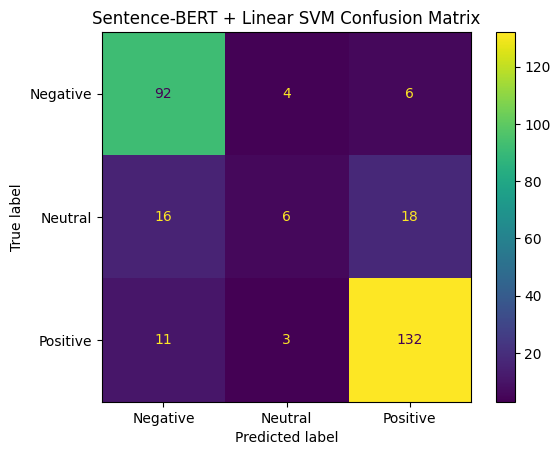

In [85]:
cm_sbert = confusion_matrix(y_test, y_pred_sbert)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_sbert,
    display_labels=sorted(y_test.unique())
)

disp.plot()
plt.title("Sentence-BERT + Linear SVM Confusion Matrix")
plt.show()

## **Final Comparison**

In [86]:
# Create complete evaluation table

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "TF-IDF + Linear SVM",
        "Optimized TF-IDF + SVM",
        "Sentence-BERT + Linear SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_tfidf),
        accuracy_score(y_test, y_pred_optimized_svm),
        accuracy_score(y_test, y_pred_sbert)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_tfidf, average='weighted'),
        precision_score(y_test, y_pred_optimized_svm, average='weighted'),
        precision_score(y_test, y_pred_sbert, average='weighted')
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_tfidf, average='weighted'),
        recall_score(y_test, y_pred_optimized_svm, average='weighted'),
        recall_score(y_test, y_pred_sbert, average='weighted')
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_tfidf, average='weighted'),
        f1_score(y_test, y_pred_optimized_svm, average='weighted'),
        f1_score(y_test, y_pred_sbert, average='weighted')
    ]
})

# Round values to 4 decimal places
model_comparison = model_comparison.round(4)

print(model_comparison)

                        Model  Accuracy  Precision  Recall  F1-Score
0         Logistic Regression    0.7743     0.7167  0.7743    0.7310
1         TF-IDF + Linear SVM    0.7743     0.7434  0.7743    0.7544
2      Optimized TF-IDF + SVM    0.7882     0.7558  0.7882    0.7639
3  Sentence-BERT + Linear SVM    0.7986     0.7669  0.7986    0.7695


### **Model Comparison – Result Interpretation**
The comparison table shows the performance of four different machine learning models used for sentiment analysis: Logistic Regression, TF-IDF + Linear SVM, Optimized TF-IDF + SVM, and Sentence-BERT + Linear SVM.

**Observations:**

**1. Logistic Regression:**

- Achieved an accuracy of 77.43%.
- Provides a good baseline for sentiment classification.
- Its weighted F1-score is 73.10%, indicating comparatively lower overall classification performance than the SVM-based models.

**2. TF-IDF + Linear SVM:**

- Achieved an accuracy of 77.43%.
- Obtained a weighted precision of 74.34% and F1-score of 75.44%.
- Performs better than Logistic Regression in terms of precision and weighted F1-score.

**3. Optimized TF-IDF + SVM:**

- Achieved an accuracy of 78.82%.
- Obtained a weighted precision of 75.58% and F1-score of 76.39%.
- Shows improved performance compared to the initial TF-IDF + Linear SVM model.
- Hyperparameter optimization helped improve the model's classification performance.

**4. Sentence-BERT + Linear SVM:**

- Achieved the highest accuracy of 79.86%.
- Obtained the highest weighted precision (76.69%) and weighted F1-score (76.95%).
- Performs best among all four models.
- Sentence-BERT embeddings help capture the semantic meaning and contextual information of text, which can improve sentiment classification.

**Final Conclusion:**

Among the four models, **Sentence-BERT + Linear SVM is the best-performing model**, achieving 79.86% accuracy and a weighted F1-score of 76.95%.

Optimized TF-IDF + SVM also provides strong results, showing improvement over the initial TF-IDF + Linear SVM model. Logistic Regression serves as a useful baseline for comparison.

Therefore, Sentence-BERT + Linear SVM is selected as the final model for this sentiment analysis project based on its overall evaluation performance.

### Model comparison through Visualization

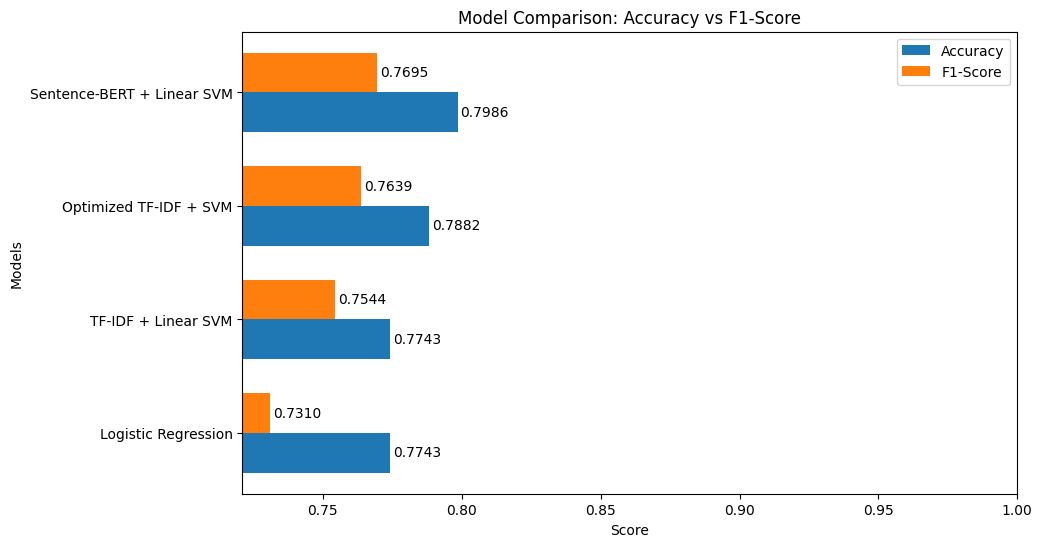

In [87]:
# Sort models based on F1-Score
best_models = model_comparison.sort_values(
    by="F1-Score",
    ascending=True
)

# Create positions for the bars
import numpy as np

y = np.arange(len(best_models))
height = 0.35

plt.figure(figsize=(10, 6))

# Accuracy bars
plt.barh(
    y - height/2,
    best_models["Accuracy"],
    height,
    label="Accuracy"
)

# F1-Score bars
plt.barh(
    y + height/2,
    best_models["F1-Score"],
    height,
    label="F1-Score"
)

# Add model names
plt.yticks(y, best_models["Model"])

# Zoom the X-axis to make small differences visible
min_score = min(
    best_models["Accuracy"].min(),
    best_models["F1-Score"].min()
)

plt.xlim(min_score - 0.01, 1)

plt.title("Model Comparison: Accuracy vs F1-Score")
plt.xlabel("Score")
plt.ylabel("Models")
plt.legend()

# Add values to the bars
for i, value in enumerate(best_models["Accuracy"]):
    plt.text(value + 0.001, i - height/2, f"{value:.4f}", va="center")

for i, value in enumerate(best_models["F1-Score"]):
    plt.text(value + 0.001, i + height/2, f"{value:.4f}", va="center")

plt.show()

### Graph Explanation

- **X-axis:** Represents the performance scores of the models.
- **Y-axis:** Represents the different sentiment analysis models.
- **Accuracy:** Measures the proportion of correctly predicted sentiment labels out of all predictions.
- **F1-Score:** Represents the balance between precision and recall, providing a useful measure of model performance.
- **Bars:** Each model has two horizontal bars, one for Accuracy and another for F1-Score, allowing easy comparison between the two metrics.

### Observations

1. Logistic Regression achieved an accuracy of **77.43%** and an F1-Score of **73.10%**, serving as the baseline model.
2. TF-IDF + Linear SVM achieved an accuracy of **77.43%** and an F1-Score of **75.44%**, showing better F1-Score performance than Logistic Regression.
3. Optimized TF-IDF + SVM improved the accuracy to **78.82%** and the F1-Score to **76.39%**, indicating an improvement after optimization.
4. Sentence-BERT + Linear SVM achieved the highest accuracy of **79.86%** and the highest F1-Score of **76.95%** among all four models.
5. The graph highlights the performance differences between the models and shows that Sentence-BERT + Linear SVM performs best overall.

### Conclusion

Based on the graph, **Sentence-BERT + Linear SVM is the best-performing model** among the four evaluated models because it achieves the highest Accuracy and F1-Score. Optimized TF-IDF + SVM also demonstrates strong performance. Therefore, Sentence-BERT + Linear SVM is selected as the final model for the sentiment analysis project.